## Mini-Project Title: Building a Text Classification Model for News Categorization

## Overview
This project focuses on using Natural Language Processing (NLP) techniques to build a text classification model for news categorization. With a large influx of news articles daily, manual categorization is inefficient. Automating this process using NLP ensures scalability, accuracy, and consistency.


## Objective
Develop an NLP-powered machine learning model that categorizes news articles into predefined categories such as Politics, Sports, Technology, Entertainment, and Health. This project covers the complete NLP pipeline, including preprocessing, feature extraction, model training, evaluation, and deployment.

## Learning Outcomes
1. Understand text preprocessing techniques like tokenization, stopword removal, and stemming/lemmatization.
2. Explore feature extraction methods such as Bag of Words, TF-IDF, and word embeddings.
3. Learn to use NLP libraries like NLTK, spaCy, and Hugging Face Transformers.
4. Experiment with NLP-specific models such as LSTM, BERT, or other transformer-based models.
5. Gain experience in deploying NLP models via APIs.


## Step 1: Define the Problem
### Task:
Understand the problem and its real-world implications. Automation of news categorization using NLP can save time, improve accuracy, and enhance user experience by organizing content effectively.

### Mini-task:
Write a brief paragraph on how NLP benefits the media industry in automating news categorization.


NLP poses many benefits in the tech world of today ranging from text classification, to translation, summarization, Question/Answering.

NLP basically will help the media organisation to efficitently and effortlessly sort their vast amounts of unstructures text into defined topics and categories that would be easier to sort after by the users. This will help to improve data analysis, content personalization and audience reach.

With text classification, NLP can identify patterns to assigned articles to categories which intend to save processing time and increase accuracy for proper decision making.


## Step 2: Data Collection
### Task:
Collect a dataset of news articles suitable for text classification. Publicly available datasets such as the AG News dataset or datasets from Kaggle can be used.

### Mini-task:
Download and load a suitable dataset for NLP tasks.


In [2]:
# Download AG News from Hugging Face
from datasets import load_dataset
import pandas as pd

# Load the AG News dataset
data = load_dataset("ag_news")


In [4]:
# Access the training and test splits
train_data = data["train"]
test_data = data["test"]

# Convert the dataset into pandas DataFrame
train_df = pd.DataFrame(train_data).sample(5000, random_state=42)
test_df = pd.DataFrame(test_data).sample(5000, random_state=42)
print(train_df.head(10))
print("\n", test_df.head(10))

                                                     text  label
71787   BBC set for major shake-up, claims newspaper L...      2
67218   Marsh averts cash crunch Embattled insurance b...      2
54066   Jeter, Yankees Look to Take Control (AP) AP - ...      1
7168    Flying the Sun to Safety When the Genesis caps...      3
29618   Stocks Seen Flat as Nortel and Oil Weigh  NEW ...      2
101425  Inter Milan seeks redemption win against Juven...      1
20441   Saudi Arabia cuts oil prices Oil prices eased ...      2
2662    Google Cuts Its IPO Price Range SAN JOSE, Cali...      0
20371   FOCUS: Santander Says HBOS Counterbid To Face ...      2
108151  HP Revises Cluster Plans HP (Quote, Chart) is ...      3

                                                    text  label
7094  Fan v Fan: Manchester City-Tottenham Hotspur T...      1
1017  Paris Tourists Search for Key to 'Da Vinci Cod...      0
2850  Net firms: Don't tax VoIP The Spanish-American...      3
1452  Dependent species risk ex

In [5]:
# Examine the shape of the data
print(train_df.shape, "\n")
print(test_df.shape)

(5000, 2) 

(5000, 2)


In [6]:
# Check the data statistics
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 71787 to 32478
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    5000 non-null   object
 1   label   5000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 117.2+ KB


In [7]:
train_df.describe()

,label
count,5000.000000
mean,1.502400
std,1.110784
min,0.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,3.000000


## Step 3: Exploratory Data Analysis (EDA)
### Task:
Analyze the dataset to understand the text structure, class distribution, and any potential imbalances.

### Mini-task:
Visualize the class distribution using a bar chart and inspect a few examples of text data.

Example

```python
import pandas as pd
import matplotlib.pyplot as plt

# Convert dataset to DataFrame for easier manipulation
df = pd.DataFrame(dataset['train'])
df['label'].value_counts().plot(kind='bar')
plt.title("Class Distribution")
plt.xlabel("Category")
plt.ylabel("Frequency")
plt.show()

# Inspect a sample
print(df.head())
```

In [8]:
import matplotlib.pyplot as plt

# Map class labels (0–3) to category names
news_label = data['train'].features['label'].names
print(news_label)


['World', 'Sports', 'Business', 'Sci/Tech']


In [9]:
# Count class Distribution
train_df['label_name'] = train_df['label'].map(lambda x: news_label[x])
train_df['label_name'].value_counts()


,count
label_name,
Sports,1317
Sci/Tech,1249
Business,1224
World,1210


In [10]:
# label_names = train_df['label_name'].unique()
# print(label_names)

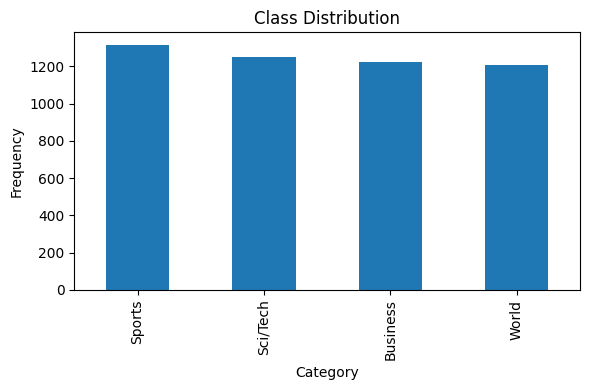

In [11]:
import matplotlib.pyplot as plt

# Plot class distribution
plt.figure(figsize=(6, 4))
train_df['label_name'].value_counts().plot(kind='bar')
plt.title("Class Distribution")
plt.xlabel("Category")
plt.ylabel("Frequency")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [12]:
# Inspect a few examples of the text data
print("\nSample texts from AG News dataset:\n")
for label in news_label:
    sample_text = train_df[train_df['label_name'] == label].sample(1).iloc[0]
    print(f"Class: {label}")
    print(f"Text: {sample_text['text'][:300]}...\n")  # show first 300 chars


Sample texts from AG News dataset:

Class: World
Text: Strong Quake Reported in Philippines - U.S. Agency (Reuters) Reuters - A strong earthquake of magnitude 6.6\hit Manila in the Philippines overnight, the U.S. Geological\Survey's earthquake center in Golden, Colorado reported on\Friday....

Class: Sports
Text: Mavericks Edge Bulls 94-93 (AP) AP - Michael Finley capped his 27-point night with a 17-foot jumper with 3.2 seconds left to lead the Dallas Mavericks to a 94-93 victory over the Chicago Bulls on Monday night....

Class: Business
Text: Stern #39;s Move Is a Signal Event Though Howard Stern #39;s defection from broadcast to satellite radio is still 16 months off, the industry is already trying to figure out what will fill the crater in ad revenue and listenership that he is expected to leave behind....

Class: Sci/Tech
Text: Shareholders rubber-stamp Microsoft payout Approval of changes to employee stock compensation paves way for \$32 billion bonanza for shareholders....



## Step 4: Text Preprocessing
### Task:
Preprocess the text data using techniques such as:
- Lowercasing
- Tokenization
- Stopword removal
- Lemmatization (optional)

### Mini-task:
Clean a small sample of the dataset using NLP libraries like NLTK or spaCy.

Example

```python
import spacy

# Load spaCy model
nlp = spacy.load("en_core_web_sm")

def preprocess(text):
    doc = nlp(text.lower())
    tokens = [token.lemma_ for token in doc if not token.is_stop and not token.is_punct]
    return " ".join(tokens)

# Apply preprocessing
df['cleaned_text'] = df['text'].apply(preprocess)
print(df[['text', 'cleaned_text']].head())
```


In [18]:
import spacy

# Load spacy model
nlp = spacy.load("en_core_web_sm")

# Define the Text Preprocessing function
def preprocess(text):
  # Convert all text to lowercase
  doc = nlp(text.lower())
  # Tokenize the text by removing stopwords, punctuations
  tokens = [token.lemma_ for token in doc if not token.is_stop and not token.is_punct]
  return " ".join(tokens)

In [21]:
# Applying Preprocessing to the 'text' column of your dataFrame
train_df['cleaned_text'] = train_df['text'].apply(preprocess)
print(train_df[['text', 'cleaned_text']].head(10))

                                                     text  \
71787   BBC set for major shake-up, claims newspaper L...   
67218   Marsh averts cash crunch Embattled insurance b...   
54066   Jeter, Yankees Look to Take Control (AP) AP - ...   
7168    Flying the Sun to Safety When the Genesis caps...   
29618   Stocks Seen Flat as Nortel and Oil Weigh  NEW ...   
101425  Inter Milan seeks redemption win against Juven...   
20441   Saudi Arabia cuts oil prices Oil prices eased ...   
2662    Google Cuts Its IPO Price Range SAN JOSE, Cali...   
20371   FOCUS: Santander Says HBOS Counterbid To Face ...   
108151  HP Revises Cluster Plans HP (Quote, Chart) is ...   

                                             cleaned_text  
71787   bbc set major shake claim newspaper london bri...  
67218   marsh avert cash crunch embattle insurance bro...  
54066   jeter yankee look control ap ap derek jeter tu...  
7168    fly sun safety genesis capsule come earth samp...  
29618   stock see flat norte

In [22]:
train_df['cleaned_text'].head(10)

,cleaned_text
71787,bbc set major shake claim newspaper london bri...
67218,marsh avert cash crunch embattle insurance bro...
54066,jeter yankee look control ap ap derek jeter tu...
7168,fly sun safety genesis capsule come earth samp...
29618,stock see flat nortel oil weigh new york reu...
101425,inter milan seek redemption win juventus early...
20441,saudi arabia cut oil price oil price ease yest...
2662,google cut ipo price range san jose calif sign...
20371,focus santander say hbo counterbid face proble...
108151,hp revise cluster plan hp quote chart drop eff...


### Step 5: Feature Engineering
### Task:
Convert the preprocessed text into numerical representations using:
- Bag of Words (BoW)
- Term Frequency-Inverse Document Frequency (TF-IDF)
- Pre-trained word embeddings (e.g., GloVe or FastText)

### Mini-task:
Compare the feature matrices generated using TF-IDF and embeddings.

Example

```python
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF Representation
vectorizer = TfidfVectorizer(max_features=5000)
tfidf_matrix = vectorizer.fit_transform(df['cleaned_text'])

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)
```

In [39]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

max_features = 5000

count_vectorizer = CountVectorizer(max_features=max_features)
count_matrix = count_vectorizer.fit_transform(train_df['cleaned_text'])

print("Count_Matrix Shape:", count_matrix.shape, "\n")
print(count_matrix)

Count_Matrix Shape: (5000, 5000) 

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 93909 stored elements and shape (5000, 5000)>
  Coords	Values
  (0, 569)	1
  (0, 4028)	1
  (0, 2703)	1
  (0, 4039)	2
  (0, 942)	1
  (0, 3065)	2
  (0, 2648)	2
  (0, 722)	1
  (0, 1144)	1
  (0, 4939)	1
  (0, 97)	1
  (0, 613)	2
  (0, 3566)	1
  (0, 727)	1
  (0, 1228)	1
  (0, 3600)	1
  (0, 83)	1
  (0, 1)	1
  (0, 4328)	1
  (0, 4936)	1
  (0, 151)	1
  (0, 4975)	1
  (0, 2137)	1
  (0, 4558)	1
  (0, 3943)	1
  :	:
  (4998, 4994)	2
  (4998, 1823)	2
  (4998, 1405)	1
  (4998, 2304)	1
  (4999, 97)	2
  (4999, 2165)	1
  (4999, 1650)	1
  (4999, 1533)	1
  (4999, 3324)	1
  (4999, 4568)	1
  (4999, 2866)	1
  (4999, 4394)	1
  (4999, 1160)	1
  (4999, 3494)	1
  (4999, 4814)	1
  (4999, 1382)	1
  (4999, 2552)	1
  (4999, 33)	1
  (4999, 4387)	1
  (4999, 2275)	1
  (4999, 961)	1
  (4999, 1718)	1
  (4999, 3148)	1
  (4999, 2803)	2
  (4999, 4611)	1


In [42]:
# Term Frequency-Inverse Document Frequency (TF-IDF) Representation
vectorizer = TfidfVectorizer(max_features=max_features)
tfidf_matrix = vectorizer.fit_transform(train_df['cleaned_text'])

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)
print("\n", tfidf_matrix)

TF-IDF Matrix Shape: (5000, 5000)

 <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 93909 stored elements and shape (5000, 5000)>
  Coords	Values
  (0, 569)	0.21974052060907992
  (0, 4028)	0.13603847383449694
  (0, 2703)	0.14632855074547177
  (0, 4039)	0.3915661752014092
  (0, 942)	0.14368112530045493
  (0, 3065)	0.37215608535623834
  (0, 2648)	0.2958175499753973
  (0, 722)	0.14602240137377545
  (0, 1144)	0.19418577157322278
  (0, 4939)	0.11075940160446876
  (0, 97)	0.06936859110161749
  (0, 613)	0.25263211139531316
  (0, 3566)	0.16172930394922827
  (0, 727)	0.23362590832330982
  (0, 1228)	0.13998341179505713
  (0, 3600)	0.1341453825603358
  (0, 83)	0.18607804267811917
  (0, 1)	0.14396383702713847
  (0, 4328)	0.1506273031144232
  (0, 4936)	0.21626083872051144
  (0, 151)	0.24021827172888677
  (0, 4975)	0.09602092815114971
  (0, 2137)	0.17370802045341593
  (0, 4558)	0.11545230736370414
  (0, 3943)	0.0764540206578201
  :	:
  (4998, 4994)	0.4902285191084503
  (4998, 1823)	0.3

## Step 6: Model Training Using NLP Models
### Task:
Train a machine learning model using features derived from NLP techniques. You can use classical models like Logistic Regression or advanced models like LSTMs or transformers.

### Mini-task:
Train a simple logistic regression model on the TF-IDF features.

```python
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(tfidf_matrix, df['label'], test_size=0.2, random_state=42)

# Logistic Regression Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predictions
accuracy = model.score(X_test, y_test)
print(f"Model Accuracy: {accuracy * 100:.2f}%")
```


In [43]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(tfidf_matrix, train_df['label'], test_size=0.2, random_state=42)

# Logistic Regression Model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predictions
accuracy = model.score(X_test, y_test)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 87.70%


### Optional: Fine-Tune a BERT Model
Train a transformer-based model using the Hugging Face `transformers` library for state-of-the-art results in text classification.

In [44]:
!pip install transformers accelerate datasets
!pip install transformers datasets torch evaluate scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.0 MB/s eta 0:00:00


In [48]:
import numpy as np
import torch
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
import evaluate
from transformers import Trainer, TrainingArguments
from datasets import Dataset

In [50]:
# Ensure you have the cleaned text and original target column
df_bert = train_df[['cleaned_text', 'label']].copy()
df_bert = df_bert.rename(columns={'cleaned_text': 'text', 'label': 'label'})

# Hugging Face's datasets library works best with standard integer labels
# We already have integer labels in the 'target' column, so no mapping is needed.
# Get the number of unique classes
num_labels = df_bert['label'].nunique()

# Convert pandas DataFrame to Hugging Face Dataset
dataset = Dataset.from_pandas(df_bert)

# Split the dataset into training and testing sets
train_test_split_dataset = dataset.train_test_split(test_size=0.2, seed=42)
train_dataset = train_test_split_dataset['train']
eval_dataset = train_test_split_dataset['test']

# Load the BERT tokenizer
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# Tokenize the datasets
def tokenize_function(examples):
    # Use truncation and padding to handle varying text lengths
    return tokenizer(examples['text'], padding='max_length', truncation=True, max_length=128) # Adjust max_length as needed

tokenized_train_dataset = train_dataset.map(tokenize_function, batched=True)
tokenized_eval_dataset = eval_dataset.map(tokenize_function, batched=True)

# Remove the original 'text' column as it's no longer needed after tokenization
tokenized_train_dataset = tokenized_train_dataset.remove_columns(['text'])
tokenized_eval_dataset = tokenized_eval_dataset.remove_columns(['text'])

# Rename the 'label' column to 'labels' as required by the Hugging Face trainer
tokenized_train_dataset = tokenized_train_dataset.rename_column("label", "labels")
tokenized_eval_dataset = tokenized_eval_dataset.rename_column("label", "labels")

# Set format for PyTorch tensors
tokenized_train_dataset.set_format('torch')
tokenized_eval_dataset.set_format('torch')


# Load the BERT model for sequence classification
model = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=num_labels)

# Define training arguments
training_args = TrainingArguments(

    output_dir='./results',          # output directory
    num_train_epochs=3,              # total number of training epochs
    per_device_train_batch_size=16,  # batch size per device during training
    per_device_eval_batch_size=64,   # batch size for evaluation
    warmup_steps=500,                # number of warmup steps for learning rate scheduler
    weight_decay=0.01,               # strength of weight decay
    logging_dir='./logs',            # directory for storing logs
    logging_steps=1000,
    eval_strategy="epoch",     # Evaluate at the end of each epoch
    save_strategy="epoch",           # Save at the end of each epoch
    load_best_model_at_end=True,     # Load the best model at the end of training
    metric_for_best_model="accuracy", # Use accuracy to determine the best model
    report_to="none"                 # Disable reporting to W&B or other services
)

# Define compute_metrics function for evaluation
metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

# Initialize the Trainer
trainer = Trainer(
    model=model,                         # the instantiated 🤗 Transformers model to be trained
    args=training_args,                  # training arguments, defined above
    train_dataset=tokenized_train_dataset,    # training dataset
    eval_dataset=tokenized_eval_dataset,      # evaluation dataset
    compute_metrics=compute_metrics      # the function to compute metrics
)

# Train the model
print("Starting BERT model training...")
trainer.train()
print("BERT model training finished.")

# Evaluate the model on the test set
print("Evaluating BERT model...")
eval_results = trainer.evaluate()
print(f"Evaluation results: {eval_results}")

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Starting BERT model training...


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,0.405836,0.880000
2,No log,0.394478,0.895000
3,No log,0.397811,0.903000


BERT model training finished.
Evaluating BERT model...


Evaluation results: {'eval_loss': 0.39781123399734497, 'eval_accuracy': 0.903, 'eval_runtime': 6.3948, 'eval_samples_per_second': 156.376, 'eval_steps_per_second': 2.502, 'epoch': 3.0}
